In [ ]:
library(dplyr)
library(Seurat)
library(patchwork)
library(ggplot2)
library(cowplot)
library(monocle)
library(tidyverse)
library(reshape2)
####GO
#载入ggplot2包；
library(ggplot2)
#install.packages("ggpubr")
#载入ggpubr包；
library(ggpubr)
library(GO.db)
library(org.Hs.eg.db)
library(clusterProfiler)
library(enrichplot)
library(ggplot2)
library(ggnewscale)
library(org.Mm.eg.db)
library(dplyr)
library(stringr)
library(ComplexUpset,lib.loc = "/home/liqian7/tools/Anaconda3/envs/R4/lib/R/library/")
options(warn=-1)####忽略警告
######upset
setwd("/DATA/User/liqian7/pienapple/06final_ST_AS_update/03figure4/03result_plot/")

In [187]:
###stage layer layer
mer <- readRDS("merge_alldata_addmodulescore.RDS")
mer <- subset(mer,subset = AD!="GC-AR")###filter GC-AR Macrophage
table(mer@meta.data$AD)
mer@meta.data$type <- "100"
mer@meta.data[which(mer@meta.data$layer_aa_da>50&mer@meta.data$layer_aa_da<=75),]$type <- "75"
mer@meta.data[which(mer@meta.data$layer_aa_da>25&mer@meta.data$layer_aa_da<=50),]$type <- "50"
mer@meta.data[which(mer@meta.data$layer_aa_da<=25),]$type <- "25"
table(mer@meta.data$type)
mer1 <- subset(mer,subset = sample=="save")
mer2 <- subset(mer1,subset = first_type=="Macrophage")


 GC-AA  GC-DA  LC-AA  LC-AR  LC-DA 
 58938  84148  87865 110027 101917 


   100     25     50     75 
107182 121413 106899 107401 

In [188]:
#####stage2 外膜 VS stage1 外膜
mer3 <- subset(mer2,subset = satge_p_all%in%c("stage1","stage2"))
table(mer3@meta.data$type)
table(mer3@meta.data$new_mp)
mer3@meta.data$cll_type <- paste0(mer3@meta.data$new_mp,mer3@meta.data$type)
table(mer3@meta.data$cll_type)
#mer4 <- subset(mer3,subset = AD!="GC-AR")
mer4 <- subset(mer3,subset = cll_type%in%c("adventitia_ms100","adventitia_ms75"))
table(mer4@meta.data$new_mp)
mer5 <- subset(mer4,subset = new_mp%in%c("adventitia_ms"))


 100   25   50   75 
4635 3389 2838 3388 


   adventitia_ms         Foamy_ms        intima_ms Other_macrophage 
            1937              655             1693             9965 


   adventitia_ms100     adventitia_ms25     adventitia_ms50     adventitia_ms75 
                900                 319                 282                 436 
        Foamy_ms100          Foamy_ms25          Foamy_ms50          Foamy_ms75 
                143                 270                 132                 110 
       intima_ms100         intima_ms25         intima_ms50         intima_ms75 
                427                 557                 323                 386 
Other_macrophage100  Other_macrophage25  Other_macrophage50  Other_macrophage75 
               3165                2243                2101                2456 


adventitia_ms 
         1336 


adventitia_ms     intima_ms 
         1937          1693 

Calculating cluster adventitia_ms

Calculating cluster intima_ms



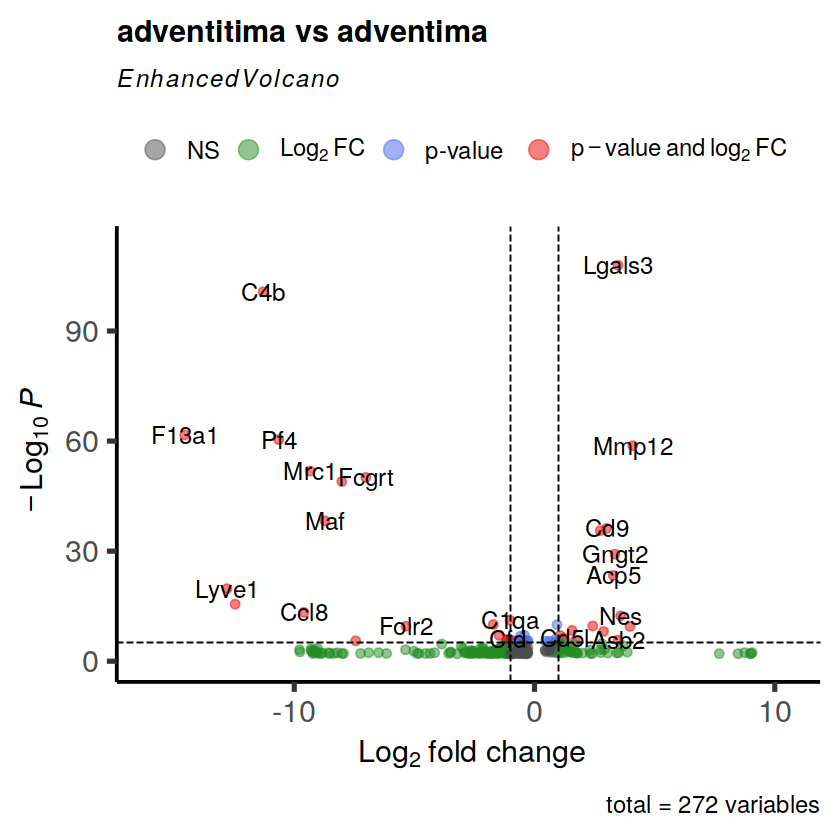

In [185]:
table(mer5@meta.data$new_mp)
Idents(mer5) <- as.factor(mer5@meta.data$new_mp)
deg = FindAllMarkers(mer5,only.pos = FALSE,
                               min.pct = 0,
                               logfc.threshold = 0.25)
deg <- subset(deg,subset = cluster=="intima_ms")
rownames(deg) <- deg$gene
p2 <- EnhancedVolcano(deg,gridlines.major = FALSE,gridlines.minor = FALSE,
                lab = rownames(deg),
                x = 'avg_log2FC',title="adventitima vs adventima",
                y = 'p_val')
p2

In [186]:
pdf("satge1_satge2_ini_adven_density.pdf",width = 8,height = 6)
print(p1)
dev.off()
pdf("satge1_satge2_ini_adven_vcan.pdf",width = 6.5,height = 6)
print(p2)
dev.off()

png 
  2

png 
  2